In [21]:
#Importing Libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.model_selection import GridSearchCV

In [22]:
#Load Dataset
df=pd.read_csv('stroke.csv')

In [23]:
#Features(PC1-PC16)
x=df.drop(columns=['Diagnosis Encoded'])

In [24]:
#Target
y=df['Diagnosis Encoded']

In [25]:
#Train Test Split

df.dropna(subset=['Diagnosis Encoded'], inplace=True)
X= df.drop(columns=['Diagnosis Encoded']) # Drop non-numeric columns
scaler=StandardScaler()
x=scaler.fit_transform(X)
y = df['Diagnosis Encoded']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [26]:
#Initialize Model
knn_model=KNeighborsClassifier(n_neighbors=5,weights='uniform')

In [27]:
#Train
knn_model.fit(x_train,y_train)

KNeighborsClassifier()

In [28]:
#Prediction
y_pred=knn_model.predict(x_test)

In [29]:
#Accuracy
print('Accuracy on test set: ',accuracy_score(y_test,y_pred))
print('Accuracy on training set: ',knn_model.score(x_train, y_train))

Accuracy on test set:  0.5456
Accuracy on training set:  0.7145


In [30]:
#Using Grid Search CV
param_grid = {'n_neighbors': range(1, 41),
               'weights':['uniform','distance'],
              'metric':['euclidean','manhattan','minkowski']}


In [31]:
grid = GridSearchCV(KNeighborsClassifier(weights='distance'), param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(x, y)
print("Best K:", grid.best_params_)

Best K: {'metric': 'manhattan', 'n_neighbors': 40, 'weights': 'distance'}


In [32]:
#Accuracy after using Grid Search CV
print('Accuracy: ',grid.best_score_)

Accuracy:  0.6812800000000001


In [33]:
#Confusion Matrix
print('\nConfusion Matrix: \n',confusion_matrix(y_test,y_pred))


Confusion Matrix: 
 [[682 568]
 [568 682]]


In [34]:
#Classification Report'
print('\nClassification Report: \n',classification_report(y_test,y_pred))


Classification Report: 
               precision    recall  f1-score   support

           0       0.55      0.55      0.55      1250
           1       0.55      0.55      0.55      1250

    accuracy                           0.55      2500
   macro avg       0.55      0.55      0.55      2500
weighted avg       0.55      0.55      0.55      2500



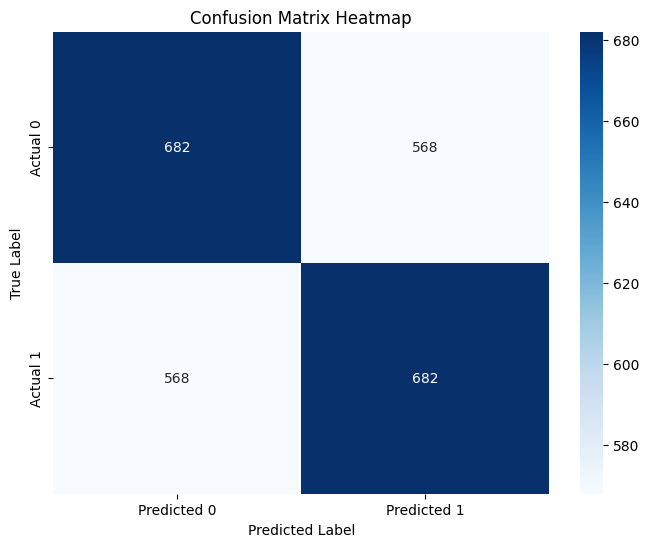

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns


# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot the confusion matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted 0', 'Predicted 1'], yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Heatmap')
plt.show()